##### Boilerplate

In [22]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

PROJECT_DIR = "/content/drive/MyDrive/DumLLM"
NOTEBOOKS_DIR = os.path.join(PROJECT_DIR, "notebooks")
SRC_DIR = os.path.join(PROJECT_DIR, "src")

os.chdir(PROJECT_DIR)

sys.path.insert(0, PROJECT_DIR)
sys.path.insert(0, SRC_DIR)
sys.path.insert(0, NOTEBOOKS_DIR)

print("DumLLM initialized!")
print("Working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DumLLM initialized!
Working directory: /content/drive/MyDrive/DumLLM


In [23]:
import importlib
import sys

importlib.invalidate_caches()

import previous_chapters
import gpt_download

importlib.reload(previous_chapters)
importlib.reload(gpt_download)

print("Modules reloaded!")
print([
    name for name in dir(previous_chapters)
    if not name.startswith("_")
])
print([
    name for name in dir(gpt_download)
    if not name.startswith("_")
])

Modules reloaded!
['DataLoader', 'Dataset', 'FeedForward', 'GELU', 'GPTDatasetV1', 'GPTModel', 'LayerNorm', 'MultiHeadAttention', 'TransformerBlock', 'create_dataloader_v1', 'generate_text_simple', 'nn', 'tiktoken', 'torch']
['TemporaryDirectory', 'download_and_load_gpt2', 'download_file', 'json', 'load_gpt2_params_from_tf_ckpt', 'np', 'os', 'requests', 'tf', 'tqdm']


# 5 Pretraning on unlabeled data

## 5.1 Evaluating generative text models

### 5.1.1 Using GPT to genenrate text

In [24]:
# import libraries
from importlib.metadata import version

pkgs = [
    "matplotlib",
    "numpy",
    "tiktoken",
    "torch",
    "tensorflow"          # for openAI's pretrained weights
]

for p in pkgs:
  print(f"{p} version: {version(p)}")

matplotlib version: 3.10.0
numpy version: 2.4.6
tiktoken version: 0.14.0
torch version: 2.14.1+cu130
tensorflow version: 2.21.0


In [25]:
from previous_chapters import GPTModel
import torch

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();

In [26]:
import tiktoken
from previous_chapters import generate_text_simple

def text_to_token_ids(text, tokenizer):
  encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
  encoded_tensor = torch.tensor(encoded).unsqueeze(0)   # add batch dimension
  return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
  flat = token_ids.squeeze(0)  # remove batch dimension
  return tokenizer.decode(flat.tolist())

In [27]:
start_context = "Every effort moves you"
tokenizer = tiktoken.encoding_for_model("gpt-2")
encoded_tensor = text_to_token_ids(start_context, tokenizer)
print(encoded_tensor)

token_ids_to_text(encoded_tensor, tokenizer)

tensor([[6109, 3626, 6100,  345]])


'Every effort moves you'

In [28]:
token_ids = generate_text_simple(
    model = model,
    idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens = 10,
    context_size = GPT_CONFIG_124M["context_length"]
)

In [29]:
token_ids.squeeze(0).shape

torch.Size([14])

In [30]:
token_ids_to_text(token_ids, tokenizer)

'Every effort moves you rentingetic wasnم refres RexMeCHicular stren'

### 5.1.2 Calculating the text generation loss: cross-entropy and perplexity

In [31]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [32]:
with torch.no_grad():
  logits = model(inputs)

In [33]:
logits.shape

torch.Size([2, 3, 50257])

In [34]:
probas = torch.softmax(logits, dim=-1)
probas.shape

torch.Size([2, 3, 50257])

In [35]:
probas

tensor([[[1.8849e-05, 1.5172e-05, 1.1687e-05,  ..., 2.2409e-05,
          6.9776e-06, 1.8776e-05],
         [9.1569e-06, 1.0062e-05, 7.8786e-06,  ..., 2.9090e-05,
          6.0103e-06, 1.3571e-05],
         [2.9877e-05, 8.8507e-06, 1.5741e-05,  ..., 3.5456e-05,
          1.4094e-05, 1.3526e-05]],

        [[1.2561e-05, 2.0538e-05, 1.4332e-05,  ..., 1.0389e-05,
          3.4784e-05, 1.4239e-05],
         [7.2731e-06, 1.7864e-05, 1.0565e-05,  ..., 2.1206e-05,
          1.1390e-05, 1.5559e-05],
         [2.9496e-05, 3.3605e-05, 4.1029e-05,  ..., 6.5249e-06,
          5.8203e-05, 1.3698e-05]]])

In [36]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


In [37]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


In [38]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:",target_probas_1)

Text 1: tensor([7.4540e-05, 3.1061e-05, 1.1563e-05])


In [39]:
text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:",target_probas_2)

Text 2: tensor([1.0337e-05, 5.6776e-05, 4.7559e-06])


In [40]:
# compute the log of all token probabilities
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -11.4798,  -9.7764, -12.2561])


In [41]:
-1 * torch.mean(log_probas)

tensor(10.7940)

In [42]:
logits_flat = logits.flatten(0, 1)
logits_flat.shape

torch.Size([6, 50257])

In [43]:
targets_flat = targets.flatten(0, 1)
targets_flat.shape

torch.Size([6])

In [44]:
torch.nn.functional.cross_entropy(logits_flat, targets_flat)

tensor(10.7940)

### 5.1.3 Calculating the training and validation set losses

In [45]:
from pathlib import Path

file_path = Path("public/the_verdict.txt")
raw_text = file_path.read_text(encoding="utf-8")

In [46]:
total_characters = len(raw_text)
print(f"Total characters: {total_characters}")

total_tokens = len(tokenizer.encode(raw_text))
print(f"Total tokens: {total_tokens}")

Total characters: 20479
Total tokens: 5145


In [47]:
from previous_chapters import create_dataloader_v1

# train-validation ratio
train_ratio = 0.9
split_idx = int(train_ratio * len(raw_text))
train_data = raw_text[:split_idx]
val_data = raw_text[split_idx:]

In [48]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size = 2,
    max_length = GPT_CONFIG_124M["context_length"],
    stride = GPT_CONFIG_124M["context_length"],
    shuffle = True,
    drop_last = True,
    num_workers = 0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size = 2,
    max_length = GPT_CONFIG_124M["context_length"],
    stride = GPT_CONFIG_124M["context_length"],
    shuffle = False,
    drop_last = False,
    num_workers = 0
)

In [49]:
print("Train loader: ")
for x,y in train_loader:
  pass
print(f"X shape: {x.shape}")
print(f"Y shape: {y.shape}")

Train loader: 
X shape: torch.Size([2, 256])
Y shape: torch.Size([2, 256])


In [50]:
print("Val loader: ")
for x,y in val_loader:
  pass
print(f"X shape: {x.shape}")
print(f"Y shape: {y.shape}")

Val loader: 
X shape: torch.Size([2, 256])
Y shape: torch.Size([2, 256])


In [51]:
train_tokens = 0
for input_batch, target_batch in train_loader:
  train_tokens += input_batch.numel()
print(f"Train tokens: {train_tokens}")

val_tokens = 0
for input_batch, target_batch in val_loader:
  val_tokens += input_batch.numel()
print(f"Val tokens: {val_tokens}")

print(f"Total tokens: {train_tokens + val_tokens}")

Train tokens: 4608
Val tokens: 512
Total tokens: 5120


In [52]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [53]:
model.to(device);

In [54]:
def calc_loss_batch(input_batch, target_batch, model, device):
  input_batch, target_batch = input_batch.to(device), target_batch.to(device)
  logits = model(input_batch)
  loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
  return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
  total_loss = 0
  if len(data_loader) == 0:
    return float("nan")
  elif num_batches is None:
    num_batches = len(data_loader)
  else:
    # reduce the number of batcches to match the total number of batches in the data loader
    # if num_batches exceeds the number of batcher in data loader
    num_batches = min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      loss = calc_loss_batch(input_batch, target_batch, model, device)
      total_loss += loss.item()
    else:
      break
  return total_loss / num_batches

In [55]:
torch.manual_seed(123)

with torch.no_grad():
  train_loss = calc_loss_loader(train_loader, model, device)
  val_loss = calc_loss_loader(val_loader, model, device)

print(f"Train loss: {train_loss}")
print(f"Val loss: {val_loss}")

Train loss: 10.987583266364204
Val loss: 10.98110580444336


In [56]:
# perplexity
perplexity = torch.exp(torch.tensor(train_loss))
print(f"Train perplexity: {perplexity}")

perplexity = torch.exp(torch.tensor(val_loss))
print(f"Val perplexity: {perplexity}")

Train perplexity: 59135.2890625
Val perplexity: 58753.48828125


## 5.2 Training an LLM

In [57]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
  # initialize lists to track losses and tokens seen
  train_losses, val_losses, track_tokens_seen = [], [], []
  tokens_seen, global_step = 0, -1

  # main training loop
  for epoch in range(num_epochs):
    model.train()   # set model to training mode

    for input_batch, target_batch in train_loader:
      optimizer.zero_grad()   # reset loss gradients from previous batch iteration
      loss = calc_loss_batch(input_batch, target_batch, model, device)
      loss.backward()   # compute gradients of loss
      optimizer.step()    # update model weights using loss gradients
      tokens_seen += input_batch.numel()
      global_step += 1

      # optional evaluation step
      if global_step % eval_freq == 0:
        train_loss, val_loss = evaluate_model(
            model, train_loader, val_loader, device, eval_iter
        )
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        track_tokens_seen.append(tokens_seen)
        print(f"Epoch {epoch+1} (Step {global_step:06d}) : Train loss {train_loss:.4f}, Val loss {val_loss:.4f}")

    # print a sample text after each epoch
    generate_and_print_sample(
        model, tokenizer, device, start_context
    )

  return train_losses, val_losses, track_tokens_seen

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
  model.eval()
  with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, eval_iter)
    val_loss = calc_loss_loader(val_loader, model, device, eval_iter)
  model.train()
  return train_loss, val_loss

def generate_and_print_sample(model, tokenizer, device, start_context):
  model.eval()
  context_size = model.pos_emb.weight.shape[0]
  encoded = text_to_token_ids(start_context, tokenizer).to(device)
  with torch.no_grad():
    token_ids = generate_text_simple(
        model = model,
        idx = encoded,
        max_new_tokens = 50,
        context_size = context_size
    )
  decoded_text = token_ids_to_text(token_ids, tokenizer)
  print(decoded_text.replace("\n", " "))
  model.train()

In [58]:

model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

In [59]:
num_epochs = 10
eval_freq = 5
eval_iter = 5
start_context = "Every effort moves you"

train_losses, val_losses, track_tokens_seen = train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer)


Epoch 1 (Step 000000) : Train loss 9.8994, Val loss 10.1118
Epoch 1 (Step 000005) : Train loss 8.1091, Val loss 8.3588
Every effort moves you the the                                                
Epoch 2 (Step 000010) : Train loss 6.7062, Val loss 7.0956
Epoch 2 (Step 000015) : Train loss 6.1197, Val loss 6.6758
Every effort moves you.                                                 
Epoch 3 (Step 000020) : Train loss 5.7148, Val loss 6.5180
Epoch 3 (Step 000025) : Train loss 5.2470, Val loss 6.5975
Every effort moves you, and, and, and, and, and, and, and of the of the of the, and, and, and, and, the, and the of the of the, and, and of the, and, and, and,
Epoch 4 (Step 000030) : Train loss 5.1785, Val loss 6.4338
Epoch 4 (Step 000035) : Train loss 4.5767, Val loss 6.3667
Every effort moves you.  "I--I--I--I--I.                  "I was the his pictures--I, I was, and I was the, in
Epoch 5 (Step 000040) : Train loss 4.2115, Val loss 6.3254
Every effort moves you know to see the fact t

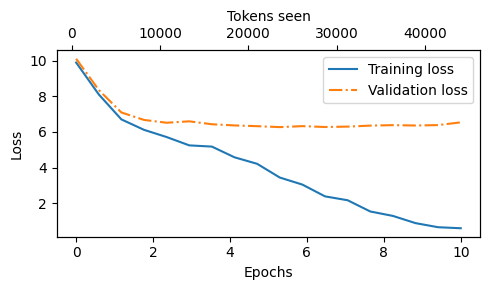

In [60]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
  fig, ax1 = plt.subplots(figsize=(5, 3))

  # plot training and validation loss against epochs
  ax1.plot(epochs_seen, train_losses, label="Training loss")
  ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
  ax1.set_xlabel("Epochs")
  ax1.set_ylabel("Loss")
  ax1.legend(loc="upper right")
  ax1.xaxis.set_major_locator(MaxNLocator(integer=True))    # only show integer labels on x-axis

  # create a second x-axis for tokens seen
  ax2 = ax1.twiny()   # create a second x-axis that shares the same y-axis
  ax2.plot(tokens_seen, train_losses, alpha=0)    # invisible plot for aligning ticks
  ax2.set_xlabel("Tokens seen")

  fig.tight_layout()
  plt.savefig("loss-plot.pdf")
  plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))

plot_losses(epochs_tensor, track_tokens_seen, train_losses, val_losses)

## 5.3 Decoding strategies to control randomness

In [61]:
model.eval()

tokenizer = tiktoken.encoding_for_model("gpt2")

token_ids = generate_text_simple(
    model = model,
    idx = text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens = 25,
    context_size = GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you?"

"Yes--quite insensible to the fact with equanimity.



"I turned to


### 5.3.1 Temperature scaling

In [62]:
vocab = {
    "closer": 0,
    "every": 1,
    "effort": 2,
    "forward": 3,
    "inches": 4,
    "moves": 5,
    "pizza": 6,
    "toward": 7,
    "you": 8,
}

inverse_vocab = {v: k for k, v in vocab.items()}

print(vocab)
print(inverse_vocab)

{'closer': 0, 'every': 1, 'effort': 2, 'forward': 3, 'inches': 4, 'moves': 5, 'pizza': 6, 'toward': 7, 'you': 8}
{0: 'closer', 1: 'every', 2: 'effort', 3: 'forward', 4: 'inches', 5: 'moves', 6: 'pizza', 7: 'toward', 8: 'you'}


In [63]:
# model(x)
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

probas = torch.softmax(next_token_logits, dim=0)
probas

tensor([6.0907e-02, 1.6313e-03, 1.0019e-04, 5.7212e-01, 3.4190e-03, 1.3257e-04,
        1.0120e-04, 3.5758e-01, 4.0122e-03])

In [64]:
next_token_id = torch.argmax(probas).item()
inverse_vocab[next_token_id]

'forward'

In [65]:
# torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
inverse_vocab[next_token_id]

'toward'

In [66]:
def print_sampled_tokens(probas):
  torch.manual_seed(123)
  sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
  sample_ids = torch.bincount(torch.tensor(sample))
  for i, freq in enumerate(sample_ids):
    print(f"{inverse_vocab[i]}: {freq}")

print_sampled_tokens(probas)

closer: 73
every: 0
effort: 0
forward: 582
inches: 2
moves: 0
pizza: 0
toward: 343


In [67]:
def softmax_with_temperature(logits, temperature):
  probas = torch.softmax(logits / temperature, dim=0)
  return probas

In [68]:
temperatures = [1, 0.1, 5]

# calculate scaled probabilities
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

for i, probas in enumerate(scaled_probas):
  print(f"Temperature {temperatures[i]}:")
  print_sampled_tokens(probas)
  print()

Temperature 1:
closer: 73
every: 0
effort: 0
forward: 582
inches: 2
moves: 0
pizza: 0
toward: 343

Temperature 0.1:
closer: 0
every: 0
effort: 0
forward: 985
inches: 0
moves: 0
pizza: 0
toward: 15

Temperature 5:
closer: 165
every: 75
effort: 42
forward: 239
inches: 71
moves: 46
pizza: 32
toward: 227
you: 103



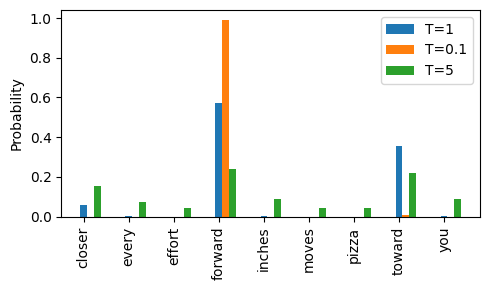

In [69]:
from IPython.core.pylabtools import figsize
# plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
  rects = ax.bar(x+i * bar_width, scaled_probas[i], bar_width, label=f"T={T}")

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

### 5.3.2 Top-k sampling

In [70]:
# model(x)
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [71]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print(top_logits)
print(top_pos)

tensor([6.7500, 6.2800, 4.5100])
tensor([3, 7, 0])


In [72]:
new_logits = torch.where(
    condition=next_token_logits<top_logits[-1],
    input=torch.tensor(float("-inf")),
    other=next_token_logits
)
new_logits

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])

In [73]:
torch.softmax(new_logits, dim=0)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])

### 5.3.3 Modify the text generation function

In [74]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):
  for _ in range(max_new_tokens):
    idx_cond = idx[:, -context_size:]

    with torch.no_grad():
      logits = model(idx_cond)

    logits = logits[:, -1, :]

    if top_k is not None:
      top_logits, top_pos = torch.topk(logits, top_k)
      new_logits = torch.where(
          condition=logits<top_logits[:,-1],
          input=torch.tensor(float("-inf")),
          other=logits
      )

    if temperature > 0.0:
      logits = logits / temperature
      probs = torch.softmax(logits, dim=-1)
      idx_next = torch.multinomial(probs, num_samples=1)

    else:
      idx_next = torch.argmax(logits, dim=-1, keepdim=True)

    if idx_next == eos_id:
      break

    idx = torch.cat((idx, idx_next), dim=1)

  return idx

In [75]:
torch.manual_seed(123)

token_ids = generate(
    model = model,
    idx = text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens = 25,
    context_size = GPT_CONFIG_124M["context_length"],
    temperature = 1.4,
    top_k = 25
  )

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you as studio were, Confeder meAnnaenezYes-- Granted rallies wish LTE Doyleenture therefore consum swordipop sketch; lou flash I


## 5.4 Loading and saving model weights in PyTorch

In [76]:
torch.save(model.state_dict(), "model.pth")

In [77]:
# loading model
test_model = GPTModel(GPT_CONFIG_124M)
test_model.load_state_dict(torch.load("model.pth", map_location=device))

<All keys matched successfully>

## 5.5 Loading pretrained weights from OpenAI

In [78]:
!pip install tqdm

In [79]:
print("tensorflow version: ",version("tensorflow"))
print("tqdm version: ",version("tqdm"))

tensorflow version:  2.21.0
tqdm version:  4.67.3


In [80]:
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


In [81]:
print("Settings: ",settings)

Settings:  {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}


In [82]:
print("Parameter dictionary keys: ",params.keys())

Parameter dictionary keys:  dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


In [83]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [84]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# copy the base configuration and update with specific model settings
model_name = 'gpt2-small (124M)'
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({'context_length': 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [85]:
# load weights params
def assign(left, right):
  if left.shape != right.shape:
    raise ValueError(f"Shape mismatch: {left.shape} != {right.shape}")
  return torch.nn.Parameter(torch.tensor(right))

In [86]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])

    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])


load_weights_into_gpt(gpt, params)
gpt.to(device);

In [90]:
torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    temperature=1.5,
    top_k=50
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you as far as vision realizes. Vinenez (Shamal reply - Cas Doyle?, 235). In lEllander Class row
